In [6]:
import pandas as pd
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
import matplotlib.pyplot as plt

# ──── Paths ──────────────────────────────────────────────────────
TRAIN_FEATURES = '../data/processed/X_train.csv'
TRAIN_TARGET   = '../data/processed/y_train.csv'
TEST_FEATURES  = '../data/processed/X_test.csv'
TEST_TARGET    = '../data/processed/y_test.csv'

STACKED_MODEL_PATH = '../models/stacked/stacked_model.pkl'
STACKED_PROBS_CSV  = '../notebooks/stacked_probabilities.csv'

# ──── Load data ──────────────────────────────────────────────────
X_train = pd.read_csv(TRAIN_FEATURES)
y_train = pd.read_csv(TRAIN_TARGET)['TARGET']
X_test  = pd.read_csv(TEST_FEATURES)
y_test  = pd.read_csv(TEST_TARGET)['TARGET']

# ──── Load pre-trained base models ───────────────────────────────
estimators = [
    ('lr',  joblib.load('../models/base/logisticregression.pkl')),
    ('rf',  joblib.load('../models/base/randomforest.pkl')),
    ('gb',  joblib.load('../models/base/gradientboosting.pkl')),
]

In [2]:
# ──── Define & train stacking ensemble ───────────────────────────
stacked_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=1000, class_weight='balanced'),
    cv=5,
    n_jobs=-1,
    verbose=2
)

print("Training Stacked Ensemble...")
stacked_model.fit(X_train, y_train)

Training Stacked Ensemble...


,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('lr', ...), ('rf', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...max_iter=1000)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",5
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary ` for more details.",-1
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",2
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0I

In [3]:
# ──── Evaluate on test set ───────────────────────────────────────
stacked_probs = stacked_model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, stacked_probs)
print(f"\nStacked Ensemble ROC AUC: {auc:.4f}")

print("\nClassification Report @ 0.5 threshold:")
print(classification_report(y_test, (stacked_probs >= 0.5).astype(int)))


Stacked Ensemble ROC AUC: 0.7550

Classification Report @ 0.5 threshold:
              precision    recall  f1-score   support

           0       0.96      0.72      0.82     56538
           1       0.17      0.66      0.27      4965

    accuracy                           0.71     61503
   macro avg       0.56      0.69      0.55     61503
weighted avg       0.90      0.71      0.78     61503



In [4]:
# ──── Save model & probabilities ─────────────────────────────────
joblib.dump(stacked_model, STACKED_MODEL_PATH)
print(f"Stacked model saved to: {STACKED_MODEL_PATH}")

pd.Series(stacked_probs, name='stacked_prob').to_csv(STACKED_PROBS_CSV, index=False)
print(f"Stacked probabilities saved to: {STACKED_PROBS_CSV}")

Stacked model saved to: ../models/stacked/stacked_model.pkl
Stacked probabilities saved to: ../notebooks/stacked_probabilities.csv


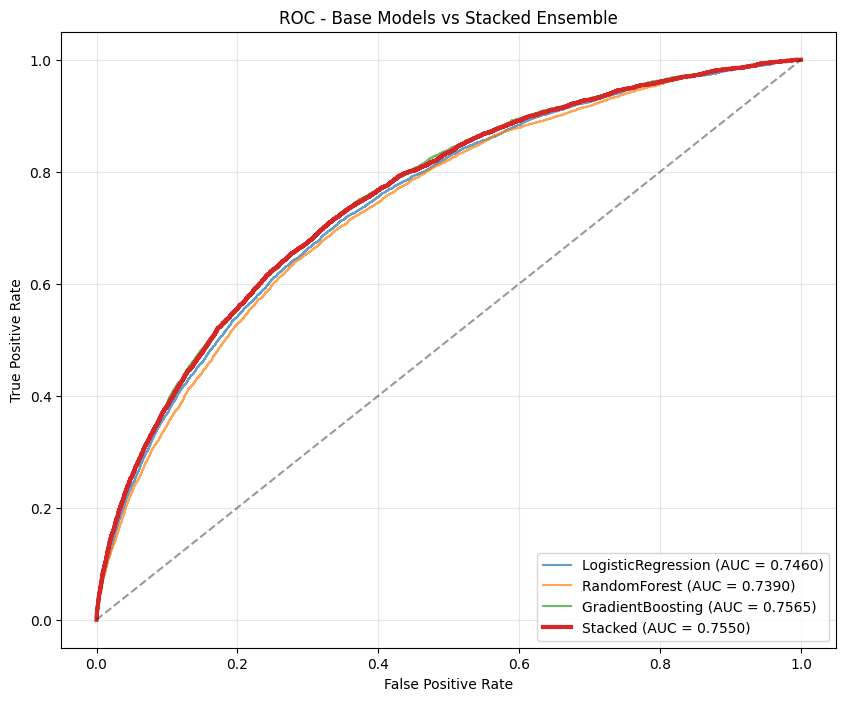

In [7]:
# ──── ROC curve comparison with bases ────────────────────────────
base_probs = pd.read_csv('../notebooks/base_probabilities.csv')

plt.figure(figsize=(10,8))

for col in base_probs.columns:
    fpr, tpr, _ = roc_curve(y_test, base_probs[col])
    plt.plot(fpr, tpr, label=f'{col} (AUC = {roc_auc_score(y_test, base_probs[col]):.4f})', alpha=0.7)

fpr, tpr, _ = roc_curve(y_test, stacked_probs)
plt.plot(fpr, tpr, label=f'Stacked (AUC = {auc:.4f})', linewidth=3)

plt.plot([0,1],[0,1], 'k--', alpha=0.4)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC - Base Models vs Stacked Ensemble')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.savefig('../reports/figures/04_stacking_roc_comparison.png', dpi=150, bbox_inches='tight')
plt.show()